In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import qmc
from scipy.integrate import solve_ivp
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, RationalQuadratic, ConstantKernel as C
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import random
import torch
import math
import torch.nn.functional as F

In [2]:
# Fix the seed

np.random.seed(42)
random.seed(42)

In [3]:


# ===================== User Settings =====================

Mr = 10.0 # robot mass
Tsim = 20.0 # simulation time in [s] #it was 60s
Ts = 0.05 # smapling time in [s], original 0.05 ms
num_samples = 10000 # number of samples in paramter space: 220
train_fraction = 0.80
peak_metric = 'max'  # 'max' or 'maxabs'



param_names = ['Kb', 'Kr', 'Mb', 'hb', 'hr', 'f0', 'f1', 'A_sin', 'x_r_start']

# Parameter ranges used for sampling

lb = np.array([100, 100, 10, 0.1, 0.1, 1e-4, 3, 0.1, 0.3])
ub = np.array([5000, 5000, 100, 0.3, 1.1, 1e-2, 10, 0.2, 0.5])




In [4]:
print(len(param_names))
print(lb.shape)
print(ub.shape)

9
(9,)
(9,)


In [5]:
# sampling the parameters

sampler = qmc.LatinHypercube(d=len(lb), seed=42) # this creates the sampler of dimension d
sample = sampler.random(n=num_samples) #this actually sample randomly within 0,1
X = qmc.scale(sample, lb, ub) # this scale the 0,1 results to our values

In [6]:
print(X.shape)
#print(sample) # this hould be 0 and 1 and in between
print(X) # our values

(10000, 9)
[[5.75900762e+02 2.28654950e+02 6.81142726e+01 ... 5.73156720e+00
  1.50012139e-01 4.37017438e-01]
 [4.95518931e+03 6.21178309e+02 1.13146591e+01 ... 3.72154093e+00
  1.27584454e-01 4.62498724e-01]
 [1.90524446e+03 1.76030048e+03 5.47501772e+01 ... 5.70775513e+00
  1.82108054e-01 4.91550666e-01]
 ...
 [1.72710990e+03 7.79065077e+02 5.83335447e+01 ... 4.54603437e+00
  1.98454172e-01 3.29124661e-01]
 [4.01012907e+03 3.05959248e+03 3.66423178e+01 ... 9.32660502e+00
  1.60852352e-01 4.76033476e-01]
 [2.27158968e+03 1.78239621e+03 4.86504995e+01 ... 6.77262189e+00
  1.14400092e-01 4.88396058e-01]]


In [7]:
# To simulate the system we need:
# - a function that describes the dynamic, "system dynamics"
# - the solver for the dynamical system, "simulate_peak_joint_position"
def chirp_signal(t, f0, f1, Tsim, A):
    """Generates a linear chirp signal."""
    k = (f1 - f0) / Tsim
    phi = 2 * np.pi * (f0 * t + 0.5 * k * t**2)
    return A * np.cos(phi)

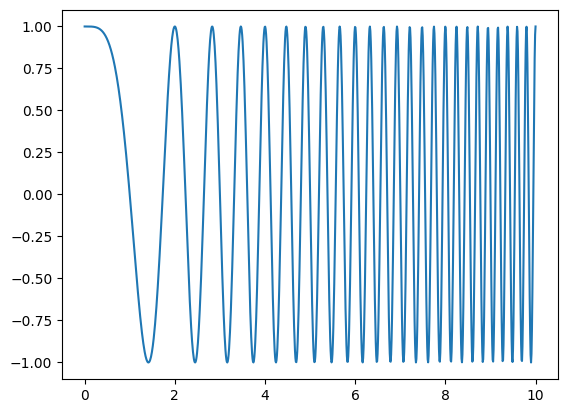

In [8]:
t_try = np.linspace(0,10,1000)
Chirp  =  chirp_signal(t_try,0,5,10,1)

Chirp.shape

plt.figure()
plt.plot(t_try,Chirp)
plt.show()

In [9]:
#chekcing what dict() does
p = dict(zip(param_names, X[150,:])) # create the dictionary
p

{'Kb': np.float64(3765.300572226375),
 'Kr': np.float64(1619.5695187394883),
 'Mb': np.float64(28.80744042578884),
 'hb': np.float64(0.1114739240676318),
 'hr': np.float64(0.47561256657436657),
 'f0': np.float64(0.008765446269348028),
 'f1': np.float64(8.888035679789365),
 'A_sin': np.float64(0.10646536324285319),
 'x_r_start': np.float64(0.3668661974646084)}

In [10]:
def system_dynamics(t, state, p, Mr):
    """Two-mass spring-damper system ODE."""
    xb, v_xb, xr, v_xr = state # state vector organised as [xb, v_xb, xr, v_xr]

    # xr is relative to the base

    # Extract params: WATCH OUT "p" is defined after as a dictionary

    Kb, Kr, Mb, hb, hr = p['Kb'], p['Kr'], p['Mb'], p['hb'], p['hr']
    A_sin, f0, f1 = p['A_sin'], p['f0'], p['f1']
    xr_start = p['x_r_start']

    # Active robot command (chirp position): that is compute the chirp signal
    x_cmd = xr_start + chirp_signal(t, f0, f1, Tsim, A_sin) # watch out for the sign

    cb = 2 * hb * Mb * np.sqrt(Kb / Mb)
    cr = 2 * hr * Mr * np.sqrt(Kr / Mr)

    # Equations of motion
    # Note: Assuming robot is controlled to follow x_cmd relative to base

    # For a surrogate model, we simulate the coupled ODE:
    a_b = (-Kr*x_cmd+Kr*xr+cr*v_xr-cb*v_xb-Kb*xb)/Mb

    # Simplified robot tracking dynamics
    a_r = (-Kr*xr-cr*v_xr+Kr*x_cmd)/Mr-a_b
    # it returns the left end side of the equation

    return [v_xb, a_b, v_xr, a_r]

In [11]:
def simulate_peak_joint_position(params_vec):

    # INPUT: "params_vec", it's the vector of parameters (1,9)

    p = dict(zip(param_names, params_vec)) # create the dictionary
    t_eval = np.arange(0, Tsim, Ts) # this is useful to state which points to take during the integration algorithm
    y0 = [0, 0, p['x_r_start'], 0] # initial condition of the state

    sol = solve_ivp(system_dynamics, [0, Tsim], y0, t_eval=t_eval, args=(p, Mr), method='RK45')


    # Output y = xb + xr
    # RECALL we organized the state as [xb, v_xb, xr, v_xr]
    # xb is sol.y[0], xr is sol.y[2]
    y_signal = sol.y[0] + sol.y[2] # this is the whole time history

    # we take just the max of the time history

    if peak_metric == 'maxabs':
        return np.max(np.abs(y_signal)), y_signal

    return np.max(y_signal), y_signal, sol.y[0], sol.y[2]

In [12]:
# simulate for 1 set of parameters

max_disp, y_signal, xb, xr = simulate_peak_joint_position(X[0,:])
y_signal = np.array(y_signal)
y_signal.shape
print(xb.shape, xr.shape)
xb = xb.reshape(1,-1)
xr = xr.reshape(1,-1)
y_riga_1200 = np.concatenate([xb, xr], axis=1)
print(y_riga_1200.shape)



(400,) (400,)
(1, 800)


In [13]:
# simulate for ALL the parameters we sampled

Y_MAT = []
Y_max = []
dof_mat = []

for i in range(len(X)):
    max_sig, y_signalv1,xb,xr = simulate_peak_joint_position(X[i,:])
    xb = xb.reshape(1,-1)
    xr = xr.reshape(1,-1)
    conc_sol = np.concatenate([xb, xr], axis=1)
    conc_sol_np = np.array(conc_sol)
    Y_MAT.append(y_signalv1)
    Y_max.append(max_sig)
    dof_mat.append(conc_sol_np) # ==============================================

print(np.array(Y_MAT).shape)
print(np.array(Y_max).shape)
dof_mat = np.vstack(dof_mat)
print(np.array(dof_mat).shape)

Y_MAT = np.vstack(Y_MAT)
Y_max = np.array(Y_max) # also peaks are stored in an array

print(Y_MAT.shape)
print(Y_max.shape)

nc = Y_MAT.shape[1] # number of time steps in the simulation

(10000, 400)
(10000,)
(10000, 800)
(10000, 400)
(10000,)


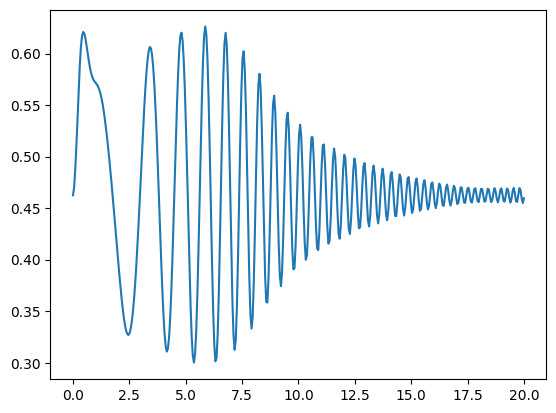

In [14]:
# visualization of some trajectories

t_plot = np.linspace(0,Tsim, np.size(Y_MAT,1))


plt.figure()
plt.plot(t_plot,Y_MAT[1,:])
plt.show()

In [15]:
from scipy.optimize import differential_evolution

# Creiamo una funzione obiettivo che restituisce il valore NEGATIVO del picco
# (perché differential_evolution minimizza, quindi minimizzare il negativo equivale a massimizzare)
def objective_function(params_vec):
    max_sig, _, _, _ = simulate_peak_joint_position(params_vec)
    return -max_sig

# Definiamo i confini (bounds) per le 9 dimensioni
bounds = list(zip(lb, ub))

# Lanciamo l'ottimizzazione
res = differential_evolution(objective_function, bounds, seed=42, maxiter=50, popsize=15)

print("Maximum displacement:", -res.fun)
print("Optimal parameters:", res.x)

Maximum displacement: 1.577218165170387
Optimal parameters: [4.88912060e+03 2.61795383e+03 1.00000000e+01 1.00000000e-01
 1.00000000e-01 1.00000000e-04 3.00000000e+00 2.00000000e-01
 5.00000000e-01]


In [16]:
print('='*50)
print('Optimal parameters found by differential evolution:')
print('maximum displacement:', -res.fun)
print('Optimal parameters:')
for i, param in enumerate(['Kb', 'Kr', 'Mb', 'hb', 'hr', 'f0', 'f1', 'A_sin', 'x_r_start']):
    print(f'{param}: {res.x[i]}')

Optimal parameters found by differential evolution:
maximum displacement: 1.577218165170387
Optimal parameters:
Kb: 4889.120601532053
Kr: 2617.95382872168
Mb: 10.0
hb: 0.1
hr: 0.1
f0: 0.0001
f1: 3.0
A_sin: 0.2
x_r_start: 0.5


In [17]:
# ==============================================================================
# INVERSE PROBLEM SETTINGS
# ==============================================================================

# 1. Definiamo i valori FISSI dei 3 parametri della base
#    Esempio: Kb = 2500, Mb = 50, hb = 0.2
fixed_base_params = {
    'Kb': res.x[0],
    'Mb': res.x[2],
    'hb': res.x[3]
}

# 2. Definiamo lo spostamento target desiderato
y_target = 1.12  # es. vogliamo un peak displacement di 0.8 m

# 3. Mappiamo i parametri variabili (i restanti 6)
free_param_names = ['Kr', 'hr', 'f0', 'f1', 'A_sin', 'x_r_start']

# Estraiamo i corrispondenti lower e upper bound per i 6 parametri liberi
free_indices = [1, 4, 5, 6, 7, 8]  # Indici di ['Kr', 'hr', 'f0', 'f1', 'A_sin', 'x_r_start']
lb_free = lb[free_indices]
ub_free = ub[free_indices]

# ==============================================================================
# INVERSE OBJECTIVE FUNCTION
# ==============================================================================

def inverse_objective_function(free_params_vec):
    """
    free_params_vec: vettore con 6 elementi [Kr, hr, f0, f1, A_sin, x_r_start]
    """
    # Ricostruiamo il vettore completo da 9 parametri
    full_params_dict = {
        'Kb': fixed_base_params['Kb'],
        'Kr': free_params_vec[0],
        'Mb': fixed_base_params['Mb'],
        'hb': fixed_base_params['hb'],
        'hr': free_params_vec[1],
        'f0': free_params_vec[2],
        'f1': free_params_vec[3],
        'A_sin': free_params_vec[4],
        'x_r_start': free_params_vec[5]
    }
    
    # Prepariamo il vettore nell'ordine originale richiesto da simulate_peak_joint_position
    full_params_vec = [full_params_dict[name] for name in param_names]
    
    # Simuliamo il sistema
    max_sig, _, _, _ = simulate_peak_joint_position(full_params_vec)
    
    # Minimizziamo lo scarto quadratico dal target (oppure errore assoluto: abs(max_sig - y_target))
    error = (max_sig - y_target)**2
    return error

# ==============================================================================
# OPTIMIZATION RUN
# ==============================================================================

bounds_free = list(zip(lb_free, ub_free))

res_inverse = differential_evolution(
    inverse_objective_function, 
    bounds_free, 
    seed=42, 
    maxiter=50, 
    popsize=15,
    atol=1e-4,  # Tolleranza di arresto
    tol=1e-4
)

# ==============================================================================
# RESULTS & VERIFICATION
# ==============================================================================

print("\n" + "="*50)
print("INVERSE PROBLEM RESULTS")
print("="*50)
print(f"Target displacement: {y_target}")
print(f"Residual Square Error: {res_inverse.fun:.6e}")

# Verifichiamo il valore effettivo simulando i parametri trovati
best_free_params = res_inverse.x
full_opt_dict = {
    'Kb': fixed_base_params['Kb'],
    'Kr': best_free_params[0],
    'Mb': fixed_base_params['Mb'],
    'hb': fixed_base_params['hb'],
    'hr': best_free_params[1],
    'f0': best_free_params[2],
    'f1': best_free_params[3],
    'A_sin': best_free_params[4],
    'x_r_start': best_free_params[5]
}

full_opt_vec = [full_opt_dict[name] for name in param_names]

achieved_max, _, _, _ = simulate_peak_joint_position(full_opt_vec)
print(f"Achieved peak displacement: {achieved_max:.5f}")
print(f"Absolute Error: {abs(achieved_max - y_target):.5f}")

print("\nFound Parameters:")
for k, v in full_opt_dict.items():
    tag = "(FIXED)" if k in fixed_base_params else "(OPTIMIZED)"
    print(f"  {k:10s}: {v:10.4f} {tag}")


INVERSE PROBLEM RESULTS
Target displacement: 1.12
Residual Square Error: 2.684523e-10
Achieved peak displacement: 1.12002
Absolute Error: 0.00002

Found Parameters:
  Kb        :  4889.1206 (FIXED)
  Kr        :  4315.1827 (OPTIMIZED)
  Mb        :    10.0000 (FIXED)
  hb        :     0.1000 (FIXED)
  hr        :     0.1165 (OPTIMIZED)
  f0        :     0.0029 (OPTIMIZED)
  f1        :     9.3505 (OPTIMIZED)
  A_sin     :     0.1723 (OPTIMIZED)
  x_r_start :     0.4906 (OPTIMIZED)


### Comparison on more targets

In [ ]:
# COMPARISON FOR MORE TARGETS WITH THE BEST BASE WE FOUND

import numpy as np
import pandas as pd
from scipy.optimize import differential_evolution

# ==============================================================================
# INVERSE PROBLEM SETTINGS (MULTI-TARGET)
# ==============================================================================

# 1. Valori FISSI dei parametri di base
fixed_base_params = {
    "Kb": res.x[0],
    "Mb": res.x[2],
    "hb": res.x[3],
}

# 2. Vettore dei target desiderati (da 0.75 a 1.50 m)
target_vec = np.arange(0.75, 1.5, 0.02)

# 3. Mappatura parametri variabili
free_param_names = ["Kr", "hr", "f0", "f1", "A_sin", "x_r_start"]
free_indices = [1, 4, 5, 6, 7, 8]
lb_free = lb[free_indices]
ub_free = ub[free_indices]
bounds_free = list(zip(lb_free, ub_free))

# ==============================================================================
# INVERSE OBJECTIVE FUNCTION (CON TARGET DINAMICO)
# ==============================================================================


def inverse_objective_function(free_params_vec, current_target):
    """Calcola l'errore quadratico rispetto al target corrente passato come argomento."""
    full_params_dict = {
        "Kb": fixed_base_params["Kb"],
        "Kr": free_params_vec[0],
        "Mb": fixed_base_params["Mb"],
        "hb": fixed_base_params["hb"],
        "hr": free_params_vec[1],
        "f0": free_params_vec[2],
        "f1": free_params_vec[3],
        "A_sin": free_params_vec[4],
        "x_r_start": free_params_vec[5],
    }

    full_params_vec = [full_params_dict[name] for name in param_names]

    # Simulazione dinamica ODE
    max_sig, _, _, _ = simulate_peak_joint_position(full_params_vec)

    # Scarto quadratico dal target di questa iterazione
    return (max_sig - current_target) ** 2


# ==============================================================================
# OPTIMIZATION LOOP OVER TARGET VECTOR
# ==============================================================================

achieved_vec = []  # Conterrà i massimi effettivamente raggiunti dalla ODE
results_history = []  # Conterrà il dizionario completo dei parametri per ciascun target

print(
    f"--- Inizio Ottimizzazione Inversa per {len(target_vec)} Target ---\n"
)

for i, t_val in enumerate(target_vec):
    # Eseguiamo la Differential Evolution passando il target corrente in args
    res_inverse = differential_evolution(
        inverse_objective_function,
        bounds_free,
        args=(t_val,),  # Passaggio dinamico del target
        seed=42 + i,
        maxiter=50,
        popsize=15,
        atol=1e-4,
        tol=1e-4,
    )

    # Estrazione dei parametri ottimali trovati per questo target
    best_free_params = res_inverse.x
    full_opt_dict = {
        "Kb": fixed_base_params["Kb"],
        "Kr": best_free_params[0],
        "Mb": fixed_base_params["Mb"],
        "hb": fixed_base_params["hb"],
        "hr": best_free_params[1],
        "f0": best_free_params[2],
        "f1": best_free_params[3],
        "A_sin": best_free_params[4],
        "x_r_start": best_free_params[5],
    }

    # Verifica mediante simulazione finale
    full_opt_vec = [full_opt_dict[name] for name in param_names]
    achieved_max, _, _, _ = simulate_peak_joint_position(full_opt_vec)

    # Salviamo il valore massimo raggiunto
    achieved_vec.append(achieved_max)

    # Creiamo un record completo con target, valore ottenuto e tutti i 9 parametri
    record = {"target_desired": t_val, "achieved_max": achieved_max}
    record.update(full_opt_dict)
    results_history.append(record)

    # Log a schermo dell'avanzamento
    err_abs = abs(achieved_max - t_val)
    print(
        f"[{i+1:02d}/{len(target_vec)}] Target: {t_val:.2f} m | Raggiunto: {achieved_max:.4f} m | Errore Assoluto: {err_abs:.4f} m"
    )

# ==============================================================================
# STRUCTURING OUTPUT DATA
# ==============================================================================

# Array NumPy pronto per essere confrontato con le predizioni della Rete Neurale
Y_true_vec = np.array(achieved_vec)

# Tabella Pandas completa di tutti i risultati e parametri
df_results = pd.DataFrame(results_history)

# (Opzionale) Salvataggio in un file CSV per usi futuri
#df_results.to_csv("inverse_optimization_results.csv", index=False)

print("\n" + "=" * 50)
print("OTTIMIZZAZIONE COMPLETATA CON SUCCESSO")
print("=" * 50)
print(df_results.head())  # Mostra le prime righe del dataframe

--- Inizio Ottimizzazione Inversa per 38 Target ---

[01/38] Target: 0.75 m | Raggiunto: 0.7500 m | Errore Assoluto: 0.0000 m
[02/38] Target: 0.77 m | Raggiunto: 0.7700 m | Errore Assoluto: 0.0000 m
[03/38] Target: 0.79 m | Raggiunto: 0.7900 m | Errore Assoluto: 0.0000 m
[04/38] Target: 0.81 m | Raggiunto: 0.8100 m | Errore Assoluto: 0.0000 m
[05/38] Target: 0.83 m | Raggiunto: 0.8300 m | Errore Assoluto: 0.0000 m
[06/38] Target: 0.85 m | Raggiunto: 0.8500 m | Errore Assoluto: 0.0000 m
[07/38] Target: 0.87 m | Raggiunto: 0.8700 m | Errore Assoluto: 0.0000 m
[08/38] Target: 0.89 m | Raggiunto: 0.8900 m | Errore Assoluto: 0.0000 m
[09/38] Target: 0.91 m | Raggiunto: 0.9100 m | Errore Assoluto: 0.0000 m
[10/38] Target: 0.93 m | Raggiunto: 0.9300 m | Errore Assoluto: 0.0000 m
[11/38] Target: 0.95 m | Raggiunto: 0.9500 m | Errore Assoluto: 0.0000 m
[12/38] Target: 0.97 m | Raggiunto: 0.9700 m | Errore Assoluto: 0.0000 m
[13/38] Target: 0.99 m | Raggiunto: 0.9900 m | Errore Assoluto: 0.0000 

In [21]:
df_results
df_results.to_csv("inverse_optimization_results.csv", index=False)